# Callaway & Sant'Anna-style staggered DiD (manual ATT(g,t) implementation)

This notebook loads the **fixed analysis-ready panel** from `ROOT/out` and implements a **manual group-time ATT estimator** following the logic of Callaway & Sant'Anna for staggered adoption.

## Design choices
- **Sample window:** `2022Q1` to `2025Q4`, matching the cleaner pre/post window discussed in the proposal.
- **Comparison group:** **never-treated municipalities only**. This avoids the forbidden-comparison problem that arises when later-treated units are used as controls for earlier-treated units.
- **Base period for each cohort:** the quarter immediately before treatment, `g - 1`.
- **Inference:** municipality-level **cluster bootstrap** by `Code`.
- **Outcomes:**
  1. `outcome_price_growth` (year-over-year rent growth)
  2. `outcome_market_activity` (tenancy agreements per 10,000 inhabitants)

This notebook produces:
- group-time ATT tables `ATT(g,t)`
- overall aggregated ATT tables
- dynamic/event-time ATT tables
- CSV / Excel / LaTeX outputs in `ROOT/out`


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [2]:
def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data").exists() and (candidate / "src").exists():
            return candidate
    return start

ROOT = find_project_root()
OUT_DIR = ROOT / "out"
OUT_DIR.mkdir(parents=True, exist_ok=True)

candidate_paths = [
    OUT_DIR / "analysis_ready_panel_fixed.pkl",
    OUT_DIR / "analysis_ready_panel_fixed.jsonl",
    OUT_DIR / "analysis_ready_panel.pkl",
    OUT_DIR / "analysis_ready_panel.jsonl",
]

panel_path = next((p for p in candidate_paths if p.exists()), None)
if panel_path is None:
    raise FileNotFoundError(
        "Could not find an analysis-ready panel in ROOT/out. "
        f"Tried: {[p.name for p in candidate_paths]}"
    )

if panel_path.suffix == ".pkl":
    panel = pd.read_pickle(panel_path)
else:
    panel = pd.read_json(panel_path, lines=True)

print("ROOT:", ROOT)
print("Loaded:", panel_path)
print("Shape:", panel.shape)
panel.head()


ROOT: /home/venatio/documents/university/public-sector-2026
Loaded: /home/venatio/documents/university/public-sector-2026/out/analysis_ready_panel.pkl
Shape: (56908, 61)


,Code,Municipality,municipality_norm,Year,Quarter,quarter_num,time_index,Prices,Contracts,price_observed_raw,contracts_observed_raw,price_imputed,contracts_imputed,has_any_observed_price,has_any_observed_contracts,exclude_from_price_analysis,exclude_from_contract_analysis,has_valid_price_for_analysis,has_valid_contracts_for_analysis,Treated 1,Treated 2,Control,ever_treated,cohort,first_treat_period,first_treat_index,treated,event_time,pop_total,pop_males,pop_females,pop_native_total,pop_native_males,pop_native_females,pop_foreign_total,pop_foreign_males,pop_foreign_females,mig_total,mig_total_males,mig_total_females,mig_inflows,mig_inflows_males,mig_inflows_females,mig_outflows,mig_outflows_males,mig_outflows_females,income_tax_base,income_tax_liability,log_prices,price_growth_qoq_pct,price_growth_yoy_pct,log_price_growth_qoq,log_price_growth_yoy,contracts_per_10k,contracts_per_10k_qoq_pct,contracts_per_10k_yoy_pct,rent_to_income_proxy,annualized_rent_to_income_proxy,rent_to_tax_liability_proxy,outcome_price_growth,outcome_market_activity
0,00005,NaN,,2015,Q1,1,8061,NaN,NaN,0,0,0,0,0,0,1,1,0,0,0,0,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,00005,NaN,,2015,Q2,2,8062,NaN,NaN,0,0,0,0,0,0,1,1,0,0,0,0,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,00005,NaN,,2015,Q3,3,8063,NaN,NaN,0,0,0,0,0,0,1,1,0,0,0,0,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,00005,NaN,,2015,Q4,4,8064,NaN,NaN,0,0,0,0,0,0,1,1,0,0,0,0,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,02050,NaN,,2011,Q1,1,8045,NaN,NaN,0,0,0,0,0,0,1,1,0,0,0,0,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Panel cleaning and estimation sample

We:
- coerce key columns to numeric
- drop rows with missing municipality names
- restrict to the clean `2022-2025` estimation window
- keep the rent and contracts samples separate because valid outcome coverage differs


In [3]:
panel = panel.copy()
panel.columns = [str(c).strip() for c in panel.columns]

required_cols = [
    "Code", "Municipality", "Year", "Quarter",
    "quarter_num", "time_index",
    "ever_treated", "first_treat_index",
    "outcome_price_growth", "outcome_market_activity",
    "has_valid_price_for_analysis", "has_valid_contracts_for_analysis",
]
missing = [c for c in required_cols if c not in panel.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

panel["Code"] = panel["Code"].astype(str).str.zfill(5)
panel["Municipality"] = panel["Municipality"].astype(str)
panel["Municipality"] = panel["Municipality"].replace({"nan": np.nan, "": np.nan})
panel["Year"] = pd.to_numeric(panel["Year"], errors="coerce").astype("Int64")
panel["quarter_num"] = pd.to_numeric(panel["quarter_num"], errors="coerce").astype("Int64")
panel["time_index"] = pd.to_numeric(panel["time_index"], errors="coerce")
panel["ever_treated"] = pd.to_numeric(panel["ever_treated"], errors="coerce").fillna(0).astype(int)
panel["first_treat_index"] = pd.to_numeric(panel["first_treat_index"], errors="coerce")
panel["has_valid_price_for_analysis"] = pd.to_numeric(panel["has_valid_price_for_analysis"], errors="coerce").fillna(0).astype(int)
panel["has_valid_contracts_for_analysis"] = pd.to_numeric(panel["has_valid_contracts_for_analysis"], errors="coerce").fillna(0).astype(int)
panel["outcome_price_growth"] = pd.to_numeric(panel["outcome_price_growth"], errors="coerce")
panel["outcome_market_activity"] = pd.to_numeric(panel["outcome_market_activity"], errors="coerce")

panel = panel[panel["Municipality"].notna()].copy()
panel = panel[panel["Year"].between(2022, 2025)].copy()
panel = panel.sort_values(["Code", "Year", "quarter_num"]).reset_index(drop=True)

print("Filtered shape:", panel.shape)
print("Municipalities:", panel["Code"].nunique())
panel[["Code", "Municipality", "Year", "Quarter", "ever_treated", "first_treat_index", "outcome_price_growth", "outcome_market_activity"]].head()


Filtered shape: (15152, 61)
Municipalities: 947


,Code,Municipality,Year,Quarter,ever_treated,first_treat_index,outcome_price_growth,outcome_market_activity
0,08001,Abrera,2022,Q1,1,"8,098.0000",10.1118,58.2815
1,08001,Abrera,2022,Q2,1,"8,098.0000",5.2855,48.8304
2,08001,Abrera,2022,Q3,1,"8,098.0000",6.7388,33.8663
3,08001,Abrera,2022,Q4,1,"8,098.0000",-8.0805,40.9546
4,08001,Abrera,2023,Q1,1,"8,098.0000",-20.4975,60.2787


In [4]:
def build_cs_sample(df: pd.DataFrame, outcome_col: str, valid_col: str) -> pd.DataFrame:
    out = df.copy()
    out = out[out[valid_col] == 1].copy()
    out = out[out[outcome_col].notna()].copy()

    # keep treated + never treated only
    out = out[(out["ever_treated"] == 1) | (out["ever_treated"] == 0)].copy()

    out["G"] = np.where(out["ever_treated"] == 1, out["first_treat_index"], np.nan)
    out = out.sort_values(["Code", "time_index"]).reset_index(drop=True)
    return out

rent_sample = build_cs_sample(panel, "outcome_price_growth", "has_valid_price_for_analysis")
contracts_sample = build_cs_sample(panel, "outcome_market_activity", "has_valid_contracts_for_analysis")

print("Rent sample rows:", len(rent_sample), "| Municipalities:", rent_sample["Code"].nunique())
print("Contracts sample rows:", len(contracts_sample), "| Municipalities:", contracts_sample["Code"].nunique())


Rent sample rows: 8448 | Municipalities: 528
Contracts sample rows: 15152 | Municipalities: 947


## Manual `ATT(g,t)` estimator

For each treated cohort `g` and post-treatment quarter `t >= g`, we compute:

\[
ATT(g,t) =
\left[
E(Y_t - Y_{g-1} \mid G=g)
\right]
-
\left[
E(Y_t - Y_{g-1} \mid C=\text{never-treated})
\right]
\]

This uses the quarter immediately before treatment (`g-1`) as the cohort-specific base period and **never-treated municipalities only** as controls.


In [5]:
def estimate_att_gt(df: pd.DataFrame, outcome_col: str, unit_col: str = "Code") -> pd.DataFrame:
    work = df[[unit_col, "ever_treated", "G", "time_index", outcome_col]].copy()
    work = work.dropna(subset=["time_index"]).copy()

    treated_groups = sorted(work.loc[work["ever_treated"] == 1, "G"].dropna().unique())
    control_units = set(work.loc[work["ever_treated"] == 0, unit_col].unique())
    all_times = sorted(work["time_index"].dropna().unique())

    rows = []
    for g in treated_groups:
        base_t = g - 1
        treated_units = set(work.loc[work["G"] == g, unit_col].unique())

        for t in all_times:
            if t < g:
                continue

            sub = work[
                (work["time_index"].isin([base_t, t])) &
                (work[unit_col].isin(treated_units | control_units))
            ][[unit_col, "time_index", outcome_col]].copy()

            if sub.empty:
                continue

            wide = sub.pivot_table(
                index=unit_col,
                columns="time_index",
                values=outcome_col,
                aggfunc="first",
            )

            if base_t not in wide.columns or t not in wide.columns:
                continue

            wide = wide[[base_t, t]].dropna().copy()
            if wide.empty:
                continue

            wide["delta"] = wide[t] - wide[base_t]
            wide["treated_group"] = np.where(wide.index.isin(treated_units), 1, 0)

            treated_delta = wide.loc[wide["treated_group"] == 1, "delta"]
            control_delta = wide.loc[wide["treated_group"] == 0, "delta"]

            if len(treated_delta) == 0 or len(control_delta) == 0:
                continue

            att = treated_delta.mean() - control_delta.mean()

            rows.append({
                "g": g,
                "t": t,
                "base_t": base_t,
                "event_time": int(t - g),
                "att": float(att),
                "n_treated": int(treated_delta.shape[0]),
                "n_control": int(control_delta.shape[0]),
            })

    return pd.DataFrame(rows)


In [6]:
def weighted_mean(x, w):
    x = np.asarray(x, dtype=float)
    w = np.asarray(w, dtype=float)
    mask = np.isfinite(x) & np.isfinite(w) & (w > 0)
    if mask.sum() == 0:
        return np.nan
    return np.average(x[mask], weights=w[mask])

def aggregate_overall(att_gt: pd.DataFrame) -> pd.DataFrame:
    if att_gt.empty:
        return pd.DataFrame([{"att": np.nan, "n_cells": 0, "n_treated_weight": 0}])

    att = weighted_mean(att_gt["att"], att_gt["n_treated"])
    return pd.DataFrame([{
        "att": att,
        "n_cells": int(len(att_gt)),
        "n_treated_weight": int(att_gt["n_treated"].sum()),
    }])

def aggregate_dynamic(att_gt: pd.DataFrame) -> pd.DataFrame:
    if att_gt.empty:
        return pd.DataFrame(columns=["event_time", "att", "n_cells", "n_treated_weight"])

    out = (
        att_gt.groupby("event_time", as_index=False)
        .apply(lambda g: pd.Series({
            "att": weighted_mean(g["att"], g["n_treated"]),
            "n_cells": int(len(g)),
            "n_treated_weight": int(g["n_treated"].sum()),
        }))
        .reset_index(drop=True)
        .sort_values("event_time")
    )
    return out

def time_index_to_label(x):
    if pd.isna(x):
        return None
    x = int(x)
    year = x // 4
    q = x % 4
    return f"{year}-Q{q}"


In [7]:
rent_att_gt = estimate_att_gt(rent_sample, "outcome_price_growth")
contracts_att_gt = estimate_att_gt(contracts_sample, "outcome_market_activity")

rent_overall = aggregate_overall(rent_att_gt)
contracts_overall = aggregate_overall(contracts_att_gt)

rent_dynamic = aggregate_dynamic(rent_att_gt)
contracts_dynamic = aggregate_dynamic(contracts_att_gt)

print("Rent ATT(g,t) cells:", len(rent_att_gt))
display(rent_att_gt.head())

print("Contracts ATT(g,t) cells:", len(contracts_att_gt))
display(contracts_att_gt.head())

print("Rent overall:")
display(rent_overall)

print("Contracts overall:")
display(contracts_overall)


Rent ATT(g,t) cells: 11


,g,t,base_t,event_time,att,n_treated,n_control
0,"8,098.0000",8098,"8,097.0000",0,-7.7019,140,257
1,"8,098.0000",8099,"8,097.0000",1,-8.3870,140,257
2,"8,098.0000",8100,"8,097.0000",2,-10.1242,140,257
3,"8,098.0000",8101,"8,097.0000",3,-11.2523,140,257
4,"8,098.0000",8102,"8,097.0000",4,-6.6702,140,257


Contracts ATT(g,t) cells: 11


,g,t,base_t,event_time,att,n_treated,n_control
0,"8,098.0000",8098,"8,097.0000",0,-8.8390,140,676
1,"8,098.0000",8099,"8,097.0000",1,-8.0641,140,676
2,"8,098.0000",8100,"8,097.0000",2,-5.6719,140,676
3,"8,098.0000",8101,"8,097.0000",3,-6.4993,140,676
4,"8,098.0000",8102,"8,097.0000",4,-8.7231,140,676


Rent overall:


,att,n_cells,n_treated_weight
0,-6.4664,11,1504


Contracts overall:


,att,n_cells,n_treated_weight
0,-7.1302,11,1504


## Municipality-cluster bootstrap

Inference is obtained by resampling municipalities (`Code`) with replacement, rebuilding the panel from those sampled municipalities, and re-estimating the group-time ATT objects.


In [8]:
BOOT_REPS = 399
BOOT_SEED = 42

def bootstrap_panel_by_unit(df: pd.DataFrame, unit_col: str = "Code", seed: int = 42):
    rng = np.random.default_rng(seed)
    units = df[unit_col].dropna().unique()
    sampled = rng.choice(units, size=len(units), replace=True)

    boot_parts = []
    for i, u in enumerate(sampled):
        part = df.loc[df[unit_col] == u].copy()
        part[unit_col] = f"{u}__b{i}"
        boot_parts.append(part)

    boot = pd.concat(boot_parts, ignore_index=True)
    return boot

def bootstrap_cs(df: pd.DataFrame, outcome_col: str, reps: int = 199, seed: int = 42):
    point_att_gt = estimate_att_gt(df, outcome_col, unit_col="Code")
    point_overall = aggregate_overall(point_att_gt)
    point_dynamic = aggregate_dynamic(point_att_gt)

    overall_boot = []
    dynamic_boot_rows = []

    for b in range(reps):
        boot = bootstrap_panel_by_unit(df, unit_col="Code", seed=seed + b + 1)
        boot_att_gt = estimate_att_gt(boot, outcome_col, unit_col="Code")
        boot_overall = aggregate_overall(boot_att_gt)
        boot_dynamic = aggregate_dynamic(boot_att_gt)

        overall_boot.append(boot_overall.iloc[0]["att"] if not boot_overall.empty else np.nan)

        if not point_dynamic.empty:
            merged = point_dynamic[["event_time"]].merge(
                boot_dynamic[["event_time", "att"]],
                on="event_time",
                how="left"
            )
            merged["rep"] = b
            dynamic_boot_rows.append(merged)

    overall_boot = np.asarray(overall_boot, dtype=float)
    overall_se = np.nanstd(overall_boot, ddof=1)

    point_overall = point_overall.copy()
    point_overall["se"] = overall_se
    point_overall["z"] = point_overall["att"] / point_overall["se"]
    point_overall["p_value"] = 2 * (
        1 - pd.Series(point_overall["z"]).abs().map(
            lambda z: 0.5 * (1 + math.erf(z / np.sqrt(2)))
        )
    )
    point_overall["ci_low"] = point_overall["att"] - 1.96 * point_overall["se"]
    point_overall["ci_high"] = point_overall["att"] + 1.96 * point_overall["se"]

    if dynamic_boot_rows:
        dynamic_boot = pd.concat(dynamic_boot_rows, ignore_index=True)
        dynamic_se = (
            dynamic_boot.groupby("event_time")["att"]
            .std(ddof=1)
            .rename("se")
            .reset_index()
        )
        point_dynamic = point_dynamic.merge(dynamic_se, on="event_time", how="left")
        point_dynamic["ci_low"] = point_dynamic["att"] - 1.96 * point_dynamic["se"]
        point_dynamic["ci_high"] = point_dynamic["att"] + 1.96 * point_dynamic["se"]
    else:
        point_dynamic["se"] = np.nan
        point_dynamic["ci_low"] = np.nan
        point_dynamic["ci_high"] = np.nan

    return point_att_gt, point_overall, point_dynamic, overall_boot

rent_att_gt, rent_overall, rent_dynamic, rent_boot = bootstrap_cs(
    rent_sample, "outcome_price_growth", reps=BOOT_REPS, seed=BOOT_SEED
)
contracts_att_gt, contracts_overall, contracts_dynamic, contracts_boot = bootstrap_cs(
    contracts_sample, "outcome_market_activity", reps=BOOT_REPS, seed=BOOT_SEED + 10000
)

display(rent_overall)
display(contracts_overall)

,att,n_cells,n_treated_weight,se,z,p_value,ci_low,ci_high
0,-6.4664,11,1504,1.4126,-4.5777,0.0000,-9.2351,-3.6977


,att,n_cells,n_treated_weight,se,z,p_value,ci_low,ci_high
0,-7.1302,11,1504,0.9913,-7.1929,0.0000,-9.0732,-5.1873


In [10]:
def pval_from_z(z):
    if pd.isna(z):
        return np.nan
    cdf = 0.5 * (1 + math.erf(abs(float(z)) / np.sqrt(2)))
    return 2 * (1 - cdf)

def add_inference(overall_df: pd.DataFrame) -> pd.DataFrame:
    out = overall_df.copy()
    out["p_value"] = out["z"].map(pval_from_z)
    return out

rent_overall = add_inference(rent_overall)
contracts_overall = add_inference(contracts_overall)

def stars(p):
    if pd.isna(p):
        return ""
    if p < 0.01:
        return "***"
    if p < 0.05:
        return "**"
    if p < 0.10:
        return "*"
    return ""

summary_table = pd.DataFrame([
    {
        "Outcome": "Rent growth (YoY, pp)",
        "ATT": rent_overall.iloc[0]["att"],
        "SE": rent_overall.iloc[0]["se"],
        "p_value": rent_overall.iloc[0]["p_value"],
        "CI low": rent_overall.iloc[0]["ci_low"],
        "CI high": rent_overall.iloc[0]["ci_high"],
        "ATT (stars)": f'{rent_overall.iloc[0]["att"]:.4f}{stars(rent_overall.iloc[0]["p_value"])}',
        "N cells": int(rent_overall.iloc[0]["n_cells"]),
        "Treated weight": int(rent_overall.iloc[0]["n_treated_weight"]),
        "N municipalities": int(rent_sample["Code"].nunique()),
        "Control group": "Never treated only",
        "Window": "2022Q1-2025Q4",
        "Bootstrap reps": BOOT_REPS,
    },
    {
        "Outcome": "Tenancy agreements per 10k",
        "ATT": contracts_overall.iloc[0]["att"],
        "SE": contracts_overall.iloc[0]["se"],
        "p_value": contracts_overall.iloc[0]["p_value"],
        "CI low": contracts_overall.iloc[0]["ci_low"],
        "CI high": contracts_overall.iloc[0]["ci_high"],
        "ATT (stars)": f'{contracts_overall.iloc[0]["att"]:.4f}{stars(contracts_overall.iloc[0]["p_value"])}',
        "N cells": int(contracts_overall.iloc[0]["n_cells"]),
        "Treated weight": int(contracts_overall.iloc[0]["n_treated_weight"]),
        "N municipalities": int(contracts_sample["Code"].nunique()),
        "Control group": "Never treated only",
        "Window": "2022Q1-2025Q4",
        "Bootstrap reps": BOOT_REPS,
    },
])

summary_table

,Outcome,ATT,SE,p_value,CI low,CI high,ATT (stars),N cells,Treated weight,N municipalities,Control group,Window,Bootstrap reps
0,"Rent growth (YoY, pp)",-6.4664,1.4126,0.0000,-9.2351,-3.6977,-6.4664***,11,1504,528,Never treated only,2022Q1-2025Q4,399
1,Tenancy agreements per 10k,-7.1302,0.9913,0.0000,-9.0732,-5.1873,-7.1302***,11,1504,947,Never treated only,2022Q1-2025Q4,399


## Dynamic/event-time plots

These are optional here, but useful for inspecting how effects evolve after treatment under the group-time ATT framework.


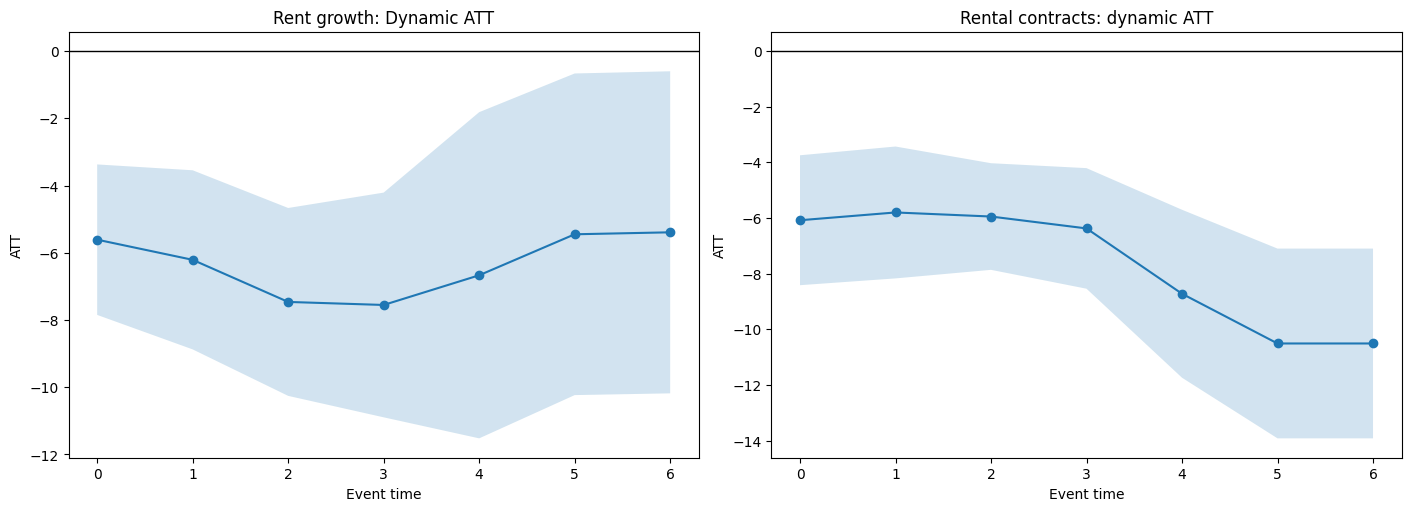

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

for ax, df_plot, title, ylab in [
    (axes[0], rent_dynamic, "Rent growth: Dynamic ATT", "ATT"),
    (axes[1], contracts_dynamic, "Rental contracts: dynamic ATT", "ATT"),
]:
    if not df_plot.empty:
        ax.axhline(0, color="black", linewidth=1)
        ax.plot(df_plot["event_time"], df_plot["att"], marker="o")
        ax.fill_between(df_plot["event_time"], df_plot["ci_low"], df_plot["ci_high"], alpha=0.2)
    ax.set_title(title)
    ax.set_xlabel("Event time")
    ax.set_ylabel(ylab)

plt.show()

## Save outputs


In [12]:
rent_att_gt_out = rent_att_gt.copy()
contracts_att_gt_out = contracts_att_gt.copy()

for df_ in [rent_att_gt_out, contracts_att_gt_out]:
    df_["g_period"] = df_["g"].map(time_index_to_label)
    df_["t_period"] = df_["t"].map(time_index_to_label)
    df_["base_period"] = df_["base_t"].map(time_index_to_label)

OUT_RENT_ATT = OUT_DIR / "csdid_rent_att_gt.csv"
OUT_CONTRACTS_ATT = OUT_DIR / "csdid_contracts_att_gt.csv"
OUT_RENT_DYNAMIC = OUT_DIR / "csdid_rent_dynamic.csv"
OUT_CONTRACTS_DYNAMIC = OUT_DIR / "csdid_contracts_dynamic.csv"
OUT_SUMMARY_CSV = OUT_DIR / "csdid_summary.csv"
OUT_SUMMARY_XLSX = OUT_DIR / "csdid_summary.xlsx"
OUT_SUMMARY_TEX = OUT_DIR / "csdid_summary.tex"

rent_att_gt_out.to_csv(OUT_RENT_ATT, index=False)
contracts_att_gt_out.to_csv(OUT_CONTRACTS_ATT, index=False)
rent_dynamic.to_csv(OUT_RENT_DYNAMIC, index=False)
contracts_dynamic.to_csv(OUT_CONTRACTS_DYNAMIC, index=False)
summary_table.to_csv(OUT_SUMMARY_CSV, index=False)
summary_table.to_excel(OUT_SUMMARY_XLSX, index=False)
OUT_SUMMARY_TEX.write_text(summary_table.to_latex(index=False, escape=False, float_format="%.4f"), encoding="utf-8")

print("Saved:")
for p in [
    OUT_RENT_ATT, OUT_CONTRACTS_ATT,
    OUT_RENT_DYNAMIC, OUT_CONTRACTS_DYNAMIC,
    OUT_SUMMARY_CSV, OUT_SUMMARY_XLSX, OUT_SUMMARY_TEX
]:
    print(" -", p)

Saved:
 - /home/venatio/documents/university/public-sector-2026/out/csdid_rent_att_gt.csv
 - /home/venatio/documents/university/public-sector-2026/out/csdid_contracts_att_gt.csv
 - /home/venatio/documents/university/public-sector-2026/out/csdid_rent_dynamic.csv
 - /home/venatio/documents/university/public-sector-2026/out/csdid_contracts_dynamic.csv
 - /home/venatio/documents/university/public-sector-2026/out/csdid_summary.csv
 - /home/venatio/documents/university/public-sector-2026/out/csdid_summary.xlsx
 - /home/venatio/documents/university/public-sector-2026/out/csdid_summary.tex
